![jupyter](img/logoItq.png)

**Nombre:** *Jair Patiño*

**Fecha:** *20/10/2026*

![jupyter](img/logoPy.png)

---
# Parte 1. ¿Qué medidas pesan más en el diagnóstico?

El dataset es el *Breast Cancer Wisconsin* que trae scikit-learn. Cada fila es una muestra de tumor y cada columna es una medida calculada sobre las células: tamaño, forma del contorno, textura, etc. Son 30 medidas y la tarea pide quedarse con las 10 más importantes.

## 1.1 Cargar los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier

# El dataset viene incluido en scikit-learn
datos = load_breast_cancer()

# Lo convierto en una tabla de pandas para ver los nombres de las columnas
df = pd.DataFrame(datos.data, columns=datos.feature_names)

print("Filas y columnas:", df.shape)
display(df.head(3))

Filas y columnas: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


Son **569 muestras** y **30 medidas** por muestra.

## 1.2 Dar vuelta al diagnóstico

scikit-learn guarda el diagnóstico como `0 = maligno` y `1 = benigno`. Yo lo doy vuelta para que `1 = maligno`. Así, un 1 significa "hay una señal de alerta", que es la lógica que va a usar la neurona más adelante.

In [2]:
print("Codificación original:", {i: str(nombre) for i, nombre in enumerate(datos.target_names)})

# Etiqueta nueva: 1 = maligno, 0 = benigno
y = 1 - datos.target

conteo = pd.Series(y).map({0: "Benigno", 1: "Maligno"}).value_counts()
print("\nCuántas muestras hay de cada tipo:")
print(conteo)
print(f"\nProporción de malignos: {y.mean():.1%}")

Codificación original: {0: 'malignant', 1: 'benign'}

Cuántas muestras hay de cada tipo:
Benigno    357
Maligno    212
Name: count, dtype: int64

Proporción de malignos: 37.3%


## 1.3 Primer ranking: correlación de Pearson

La correlación dice cuánto "acompaña" una medida al diagnóstico: si cuando la medida sube el tumor suele ser maligno, la correlación es alta. Uso el valor absoluto porque me importa la fuerza de la relación, no si es positiva o negativa.

In [3]:
correlaciones = df.apply(lambda columna: np.corrcoef(columna, y)[0, 1])

ranking_pearson = (
    correlaciones.abs()
    .sort_values(ascending=False)
    .rename("Correlación (valor absoluto)")
    .to_frame()
)

print("Las 10 medidas con mayor correlación:")
display(ranking_pearson.head(10).round(3))

Las 10 medidas con mayor correlación:


,Correlación (valor absoluto)
worst concave points,0.794
worst perimeter,0.783
mean concave points,0.777
worst radius,0.776
mean perimeter,0.743
worst area,0.734
mean radius,0.730
mean area,0.709
mean concavity,0.696
worst concavity,0.660


## 1.4 Segundo ranking: Random Forest

Un Random Forest es un conjunto de muchos árboles de decisión. Al terminar de entrenarse, cuenta cuánto ayudó cada medida a separar benignos de malignos. Esas "importancias" de las 30 medidas suman 1. Con `random_state=42` el resultado se repite igual cada vez que ejecuto el código.

Uso un segundo método porque la correlación solo detecta relaciones simples, y el bosque puede captar otras más complejas. Si los dos coinciden, la selección es más confiable.

In [4]:
bosque = RandomForestClassifier(n_estimators=200, random_state=42)
bosque.fit(df, y)

ranking_rf = (
    pd.Series(bosque.feature_importances_, index=df.columns)
    .sort_values(ascending=False)
    .rename("Importancia")
    .to_frame()
)

print("Las 10 medidas más importantes según el bosque:")
display(ranking_rf.head(10).round(3))

Las 10 medidas más importantes según el bosque:


,Importancia
worst perimeter,0.143
worst area,0.128
worst concave points,0.119
mean concave points,0.102
worst radius,0.076
mean area,0.053
mean perimeter,0.053
mean concavity,0.053
mean radius,0.042
worst concavity,0.038


## 1.5 Mi lista frente a los dos rankings

Estas son las 10 medidas con las que decidí trabajar. Las pongo al lado de los rankings para ver cuántas coinciden y en qué puesto quedó cada una.

In [5]:
mis_10 = [
    "worst concave points",
    "worst perimeter",
    "worst radius",
    "worst area",
    "mean concavity",
    "mean concave points",
    "worst texture",
    "mean perimeter",
    "mean area",
    "worst concavity",
]

top10_pearson = list(ranking_pearson.head(10).index)
top10_rf = list(ranking_rf.head(10).index)

print("Coincidencias con el top 10 de Pearson      :", len(set(mis_10) & set(top10_pearson)), "de 10")
print("Coincidencias con el top 10 de Random Forest:", len(set(mis_10) & set(top10_rf)), "de 10")
print()
print("Lo que el bosque pone en su top 10 y yo no elegí:", set(top10_rf) - set(mis_10))
print("Lo que yo elegí y el bosque no pone en su top 10:", set(mis_10) - set(top10_rf))

posiciones = pd.DataFrame({
    "Puesto en Pearson": [list(ranking_pearson.index).index(c) + 1 for c in mis_10],
    "Puesto en Random Forest": [list(ranking_rf.index).index(c) + 1 for c in mis_10],
}, index=mis_10)
display(posiciones)

Coincidencias con el top 10 de Pearson      : 9 de 10
Coincidencias con el top 10 de Random Forest: 9 de 10

Lo que el bosque pone en su top 10 y yo no elegí: {'mean radius'}
Lo que yo elegí y el bosque no pone en su top 10: {'worst texture'}


,Puesto en Pearson,Puesto en Random Forest
worst concave points,1,3
worst perimeter,2,1
worst radius,4,5
worst area,6,2
mean concavity,9,8
mean concave points,3,4
worst texture,16,13
mean perimeter,5,7
mean area,8,6
worst concavity,10,10


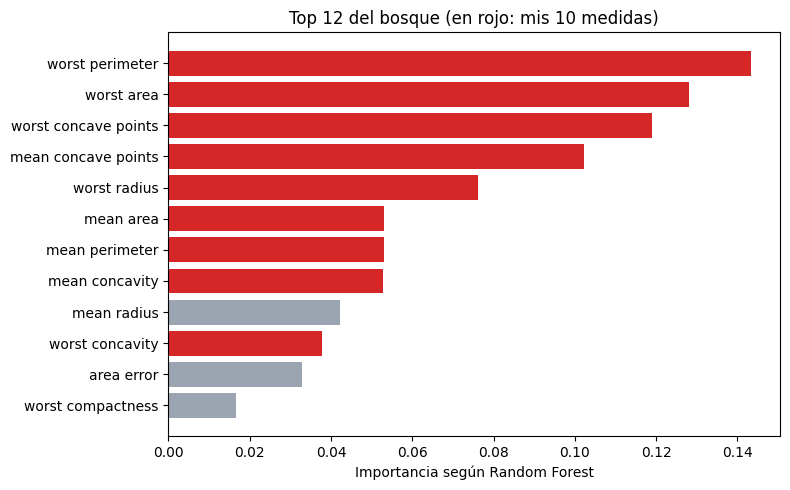

In [6]:
# Las 12 medidas más importantes del bosque; en rojo las que están en mi lista
top12 = ranking_rf.head(12)["Importancia"].sort_values()

plt.figure(figsize=(8, 5))
colores = ["#d62728" if nombre in mis_10 else "#9aa5b1" for nombre in top12.index]
plt.barh(top12.index, top12.values, color=colores)
plt.xlabel("Importancia según Random Forest")
plt.title("Top 12 del bosque (en rojo: mis 10 medidas)")
plt.tight_layout()
plt.show()

## 1.6 Cómo se reparten las medidas en benignos y malignos

Para cada una de mis 10 medidas dibujo dos histogramas, uno por tipo de tumor. Si las dos "montañas" casi no se tocan, esa medida separa bien los grupos. Si se encimen mucho, ayuda poco.

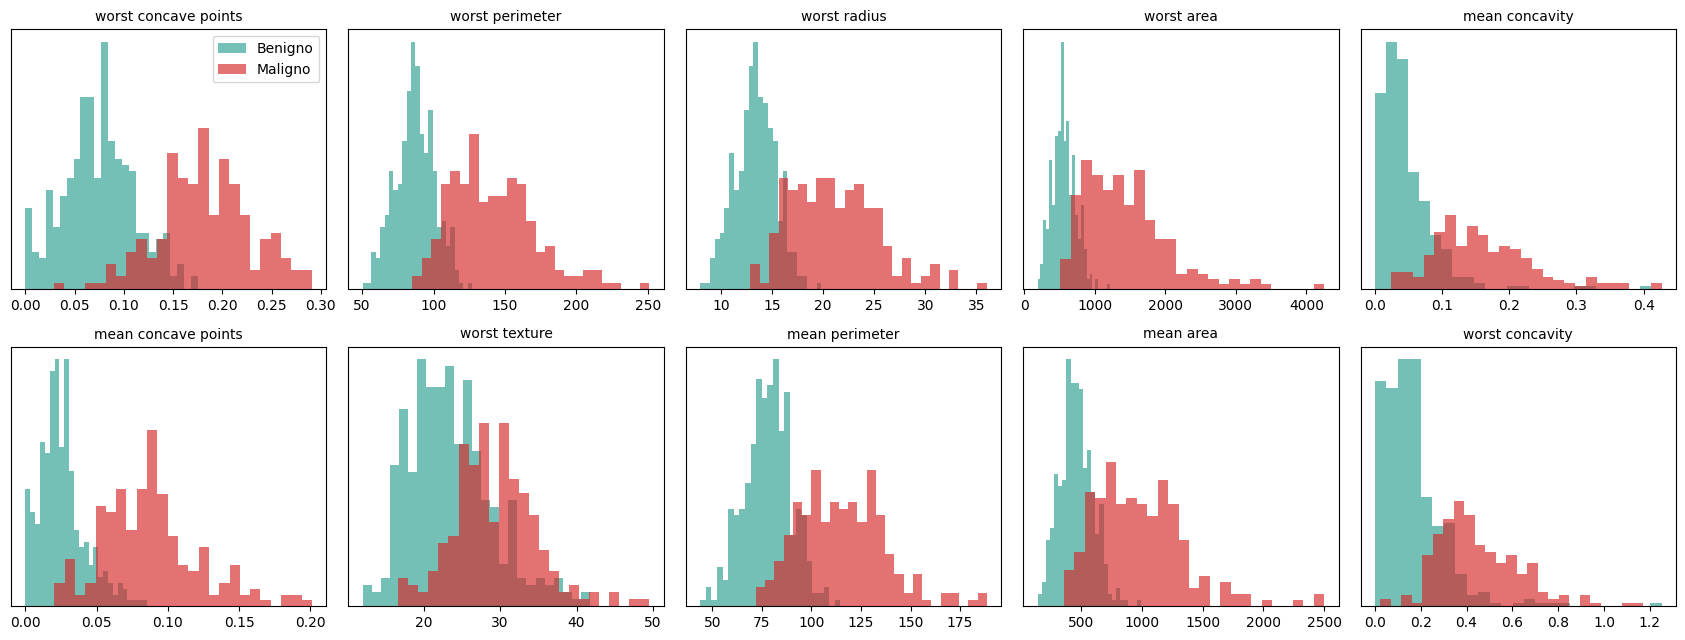

In [7]:
fig, ejes = plt.subplots(2, 5, figsize=(17, 6.5))
for eje, nombre in zip(ejes.ravel(), mis_10):
    eje.hist(df.loc[y == 0, nombre], bins=25, alpha=0.65, label="Benigno", color="#2a9d8f")
    eje.hist(df.loc[y == 1, nombre], bins=25, alpha=0.65, label="Maligno", color="#d62728")
    eje.set_title(nombre, fontsize=10)
    eje.set_yticks([])
ejes[0, 0].legend()
plt.tight_layout()
plt.show()

## 1.7 ¿Hay medidas que dicen lo mismo?

Varias medidas describen el tamaño (radio, perímetro, área), así que es normal que se parezcan entre sí. Aquí reviso cuánto se relacionan mis 10 y comparo `mean radius` y `worst texture`, que son justo la diferencia entre mi lista y la de los rankings.

In [8]:
print("Correlación entre mis 10 medidas:")
display(df[mis_10].corr().round(2))

print("mean radius   con mean perimeter:", round(df["mean radius"].corr(df["mean perimeter"]), 3))
print("worst texture con mean perimeter:", round(df["worst texture"].corr(df["mean perimeter"]), 3))

Correlación entre mis 10 medidas:


,worst concave points,worst perimeter,worst radius,worst area,mean concavity,mean concave points,worst texture,mean perimeter,mean area,worst concavity
worst concave points,1.00,0.82,0.79,0.75,0.86,0.91,0.36,0.77,0.72,0.86
worst perimeter,0.82,1.00,0.99,0.98,0.73,0.86,0.37,0.97,0.96,0.62
worst radius,0.79,0.99,1.00,0.98,0.69,0.83,0.36,0.97,0.96,0.57
worst area,0.75,0.98,0.98,1.00,0.68,0.81,0.35,0.94,0.96,0.54
mean concavity,0.86,0.73,0.69,0.68,1.00,0.92,0.30,0.72,0.69,0.88
mean concave points,0.91,0.86,0.83,0.81,0.92,1.00,0.29,0.85,0.82,0.75
worst texture,0.36,0.37,0.36,0.35,0.30,0.29,1.00,0.30,0.29,0.37
mean perimeter,0.77,0.97,0.97,0.94,0.72,0.85,0.30,1.00,0.99,0.56
mean area,0.72,0.96,0.96,0.96,0.69,0.82,0.29,0.99,1.00,0.51
worst concavity,0.86,0.62,0.57,0.54,0.88,0.75,0.37,0.56,0.51,1.00


mean radius   con mean perimeter: 0.998
worst texture con mean perimeter: 0.303


## Lo que concluyo de la Parte 1

**Mi lista coincide en 9 de 10** con el top 10 de Pearson y con el del Random Forest, así que los dos métodos respaldan mi selección.

**La diferencia está en una sola medida.** Yo incluí `worst texture`, y los dos rankings prefieren `mean radius`. `worst texture` aparece en el puesto 13 del bosque y en el 16 de Pearson.

**Por qué conservé `worst texture`.** `mean radius` tiene una correlación de 0.998 con `mean perimeter`, que ya está en mi lista, es decir, repite casi la misma información. En cambio, `worst texture` casi no se relaciona con el tamaño (correlación de 0.30), así que aporta una señal nueva. En la sección 2.7 pruebo qué efecto tiene esa decisión.

**Qué mide cada grupo de medidas elegidas:**

- *Tamaño* (`worst radius`, `worst perimeter`, `worst area`, `mean perimeter`, `mean area`): las células cancerosas se multiplican rápido y suelen ocupar más espacio.
- *Contorno* (`worst concave points`, `mean concave points`, `mean concavity`, `worst concavity`): miden las hendiduras del borde del núcleo. En las células sanas el borde es más liso.
- *Textura* (`worst texture`): mide qué tan desparejos son los tonos de gris del núcleo.
- Las medidas `worst` guardan el valor más extremo de la muestra, y en un tumor maligno basta con que una zona sea agresiva para que ese valor se dispare.

---
# Parte 2. La neurona de McCulloch-Pitts

## Cómo funciona

Una forma sencilla de entenderla es como una **lista de 10 señales de alerta**, una por cada medida. Para cada señal se hace una sola pregunta: *¿el valor de esta muestra es mayor que el valor típico de los casos de entrenamiento?* Si la respuesta es sí, se marca la señal (un 1); si no, queda sin marcar (un 0).

Después la neurona cuenta cuántas señales quedaron marcadas. Si el total llega a un número mínimo llamado **θ (theta)** o lo supera, da la alarma y declara el tumor **Maligno**. Si no llega, lo declara **Benigno**.

Hay dos decisiones que se toman al entrenar:

- **El "valor típico" de cada medida** es su **mediana** en los datos de entrenamiento. Queda guardado, y por eso la neurona puede clasificar una sola muestra que llegue desde el formulario.
- **El número θ** no lo fijo a mano. La neurona prueba todos los valores posibles (de 0 a 10) y se queda con el que más acierta en el entrenamiento.

## 2.1 Separar datos de entrenamiento y de prueba

Un termómetro no se evalúa con las mismas muestras con las que se calibró: saldría perfecto aunque midiera mal. Con la neurona pasa igual. Por eso separo **80 % de las muestras para entrenar** y guardo **20 % que la neurona nunca ve**, para medir después qué tan bien funciona de verdad. `stratify=y` hace que los dos grupos tengan la misma proporción de benignos y malignos.

In [9]:
from sklearn.model_selection import train_test_split

X = df[mis_10]   # solo mis 10 medidas

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Para entrenar:", len(X_ent), "muestras | malignos:", f"{y_ent.mean():.1%}")
print("Para probar  :", len(X_prueba), "muestras | malignos:", f"{y_prueba.mean():.1%}")

Para entrenar: 455 muestras | malignos: 37.4%
Para probar  : 114 muestras | malignos: 36.8%


## 2.2 Programar la neurona

La clase queda en su propio archivo, `neurona_mp.py`, con la celda `%%writefile`. Así el servidor de la Parte 3 importa **la misma neurona** que estoy usando aquí. Tiene tres operaciones:

- `binarizar`: marca con 1 las medidas que superan su umbral.
- `entrenar`: calcula las medianas y elige el mejor θ.
- `predict`: cuenta las marcas y decide.

In [10]:
%%writefile neurona_mp.py
"""Neurona de McCulloch-Pitts aplicada a tumores de mama.

Convención: 1 = maligno, 0 = benigno.

Idea: cada medida "levanta la mano" (1) cuando su valor es mayor que la mediana
que tuvo en los datos de entrenamiento. La neurona cuenta las manos levantadas
y, si son theta o más, da la alarma: el tumor se declara maligno.
"""
import numpy as np


class NeuronaMP:
    def __init__(self):
        self.umbrales = None            # mediana de cada columna (se calcula al entrenar)
        self.theta = None               # mínimo de manos levantadas para decir "maligno"
        self.exactitud_por_theta = {}   # exactitud que se obtuvo con cada theta probado

    def binarizar(self, X):
        """1 si el valor supera el umbral de su columna, 0 si no."""
        return (np.asarray(X) > self.umbrales).astype(int)

    def sumar(self, X):
        """Total de medidas que dieron 1 en cada fila."""
        return self.binarizar(X).sum(axis=1)

    def entrenar(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        # Paso 1: el umbral de cada columna es su mediana
        self.umbrales = np.median(X, axis=0)

        # Paso 2: probar todos los theta posibles (de 0 hasta el número de columnas)
        sumas = self.sumar(X)
        self.exactitud_por_theta = {}
        for theta in range(X.shape[1] + 1):
            prediccion = (sumas >= theta).astype(int)
            self.exactitud_por_theta[theta] = float((prediccion == y).mean())

        # Paso 3: quedarse con el theta que acierta más veces
        self.theta = max(self.exactitud_por_theta, key=self.exactitud_por_theta.get)
        return self

    def predict(self, X):
        """1 (maligno) si los votos alcanzan theta, 0 (benigno) si no."""
        return (self.sumar(X) >= self.theta).astype(int)

Overwriting neurona_mp.py


## 2.3 Entrenar

Aquí solo entra el grupo de entrenamiento. Se muestran los umbrales (las medianas) y la exactitud que habría con cada valor de θ; la neurona se queda con el mejor.

In [11]:
from neurona_mp import NeuronaMP

neurona = NeuronaMP()
neurona.entrenar(X_ent.values, y_ent)

print("Umbral de cada medida (su mediana en entrenamiento):")
print(pd.Series(neurona.umbrales, index=mis_10).round(4))

print("\nExactitud en entrenamiento con cada theta:")
tabla_theta = pd.Series(neurona.exactitud_por_theta).rename_axis("theta").to_frame("exactitud")
display(tabla_theta.round(4))

print("theta elegido:", neurona.theta)

Umbral de cada medida (su mediana en entrenamiento):
worst concave points      0.1010
worst perimeter          97.6500
worst radius             14.9200
worst area              683.4000
mean concavity            0.0594
mean concave points       0.0333
worst texture            25.4800
mean perimeter           86.1800
mean area               546.4000
worst concavity           0.2298
dtype: float64

Exactitud en entrenamiento con cada theta:


,exactitud
theta,
0,0.3736
1,0.5780
2,0.7165
3,0.7582
4,0.8132
5,0.8462
6,0.8857
7,0.9011
8,0.9121


theta elegido: 8


## 2.4 Ver una decisión paso a paso

Tomo 5 muestras de entrenamiento y muestro todo el recorrido: qué señales se marcaron (1), cuántas fueron en total, qué decidió la neurona y cuál era el diagnóstico real.

In [12]:
muestras = X_ent.head(5)

votos = pd.DataFrame(neurona.binarizar(muestras.values), columns=mis_10, index=muestras.index)
votos["suma de votos"] = neurona.sumar(muestras.values)
votos["predicción"] = neurona.predict(muestras.values)
votos["real"] = y_ent[:5]

display(votos)
print("1 = maligno, 0 = benigno")

,worst concave points,worst perimeter,worst radius,worst area,mean concavity,mean concave points,worst texture,mean perimeter,mean area,worst concavity,suma de votos,predicción,real
10,0,1,1,1,0,0,1,1,1,0,6,0,1
170,0,0,0,0,0,1,0,0,0,0,1,0,0
407,0,0,0,0,1,0,1,0,0,0,2,0,0
430,1,1,1,1,1,1,1,1,1,1,10,1,1
27,1,1,1,1,1,1,1,1,1,1,10,1,1


1 = maligno, 0 = benigno


## 2.5 Medir el resultado con los datos de prueba

Ahora uso el 20 % que la neurona no conoce. Miro tres números, porque uno solo puede engañar:

- **Exactitud:** de todas las muestras, en cuántas acertó.
- **Sensibilidad:** de los tumores que de verdad eran malignos, cuántos encontró. Es la que más me importa, porque no avisar de un tumor maligno es peor que dar una falsa alarma.
- **Precisión:** cuando dijo "maligno", qué proporción realmente lo era.

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

pred_prueba = neurona.predict(X_prueba.values)

print(f"Exactitud   : {accuracy_score(y_prueba, pred_prueba):.1%}")
print(f"Sensibilidad: {recall_score(y_prueba, pred_prueba):.1%}")
print(f"Precisión   : {precision_score(y_prueba, pred_prueba):.1%}")

matriz = confusion_matrix(y_prueba, pred_prueba)
display(pd.DataFrame(
    matriz,
    index=["Real: Benigno", "Real: Maligno"],
    columns=["Predijo: Benigno", "Predijo: Maligno"],
))

print(f"\nPara comparar: decir siempre 'benigno' acertaría el {(y_prueba == 0).mean():.1%}")

Exactitud   : 93.9%
Sensibilidad: 97.6%
Precisión   : 87.2%


,Predijo: Benigno,Predijo: Maligno
Real: Benigno,66,6
Real: Maligno,1,41



Para comparar: decir siempre 'benigno' acertaría el 63.2%


En la matriz, los números de la diagonal son los aciertos. Los otros dos son los errores:

- *Real: Maligno, predijo: Benigno* es el **falso negativo**, el error más grave.
- *Real: Benigno, predijo: Maligno* es el **falso positivo**: una falsa alarma.

## 2.6 ¿Y si θ fuera otro número?

Evalúo en los datos de prueba todos los valores posibles de θ para ver cómo cambian las métricas. Un θ más bajo detecta más malignos pero genera más falsas alarmas; uno más alto hace lo contrario.

In [14]:
filas = []
for theta in range(11):
    pred = (neurona.sumar(X_prueba.values) >= theta).astype(int)
    filas.append({
        "theta": theta,
        "exactitud": accuracy_score(y_prueba, pred),
        "sensibilidad": recall_score(y_prueba, pred, zero_division=0),
        "precisión": precision_score(y_prueba, pred, zero_division=0),
    })
display(pd.DataFrame(filas).set_index("theta").round(3))

,exactitud,sensibilidad,precisión
theta,,,
0,0.368,1.000,0.368
1,0.570,1.000,0.462
2,0.728,1.000,0.575
3,0.763,1.000,0.609
4,0.798,1.000,0.646
5,0.842,1.000,0.700
6,0.912,1.000,0.808
7,0.930,1.000,0.840
8,0.939,0.976,0.872


## 2.7 ¿Qué pasa si cambio `worst texture` por `mean radius`?

En la Parte 1 vi que esa es la única diferencia entre mi lista y la de los rankings. Entreno la neurona con las dos versiones, con el mismo reparto de datos, y comparo.

In [15]:
alternativa = [c if c != "worst texture" else "mean radius" for c in mis_10]

filas = []
for nombre, columnas in (("Mi lista (con worst texture)", mis_10),
                         ("Con mean radius en su lugar", alternativa)):
    Xe, Xp, ye, yp = train_test_split(df[columnas], y, test_size=0.2, random_state=42, stratify=y)
    n = NeuronaMP().entrenar(Xe.values, ye)
    p = n.predict(Xp.values)
    filas.append({
        "medidas usadas": nombre,
        "theta": n.theta,
        "exactitud": accuracy_score(yp, p),
        "sensibilidad": recall_score(yp, p),
        "precisión": precision_score(yp, p),
    })
display(pd.DataFrame(filas).set_index("medidas usadas").round(3))

,theta,exactitud,sensibilidad,precisión
medidas usadas,,,,
Mi lista (con worst texture),8,0.939,0.976,0.872
Con mean radius en su lugar,10,0.956,0.905,0.974


## Lo que concluyo de la Parte 2

- **θ = 8.** La neurona declara "maligno" cuando al menos 8 de las 10 medidas superan su mediana. Tiene sentido: un tumor maligno suele ser extremo en casi todas a la vez.
- **Exactitud de 93.9 %.** Si el modelo dijera siempre "benigno" acertaría el 63.2 %, así que la neurona aporta mucho más que adivinar la clase más común.
- **Sensibilidad de 97.6 %.** De los 42 tumores malignos de la prueba encontró 41. Se le escapó 1.
- **Precisión de 87.2 %.** Hizo 6 falsas alarmas: 6 tumores benignos que marcó como malignos.
- **`worst texture` o `mean radius`.** Con `mean radius` la exactitud sube a 95.6 % y la precisión a 97.4 %, pero la sensibilidad cae a 90.5 %, lo que equivale a que se escaparían unos 4 malignos en vez de 1. Prefiero conservar `worst texture`, porque dar una falsa alarma es mejor que dejar pasar un tumor maligno.
- **Límites.** El grupo de prueba tiene solo 114 muestras, así que cambiar un par de casos mueve varios puntos porcentuales. Y la neurona es un modelo muy simple, hecho con fines académicos: no sustituye un diagnóstico médico.

---
# Parte 3. El servidor con FastAPI

FastAPI es la herramienta que convierte la neurona en una aplicación a la que se puede consultar desde el navegador. El archivo `main.py` hace lo siguiente:

1. **Al encender el servidor** carga el dataset y entrena la neurona una sola vez. Así cada consulta se responde al instante, sin volver a entrenar.
2. **Ruta `GET /`**: entrega la página del formulario (`index.html`).
3. **Ruta `POST /predict`**: recibe las 10 medidas en formato JSON, las ordena igual que en el entrenamiento y devuelve tres datos: el diagnóstico, cuántas señales se marcaron (votos) y el valor de θ.
4. **Validación con Pydantic**: si llega un valor negativo, un cero donde no corresponde o falta un campo, el servidor responde con error 422 y no ejecuta la neurona.

Para encender el servidor se usa Uvicorn.

In [16]:
%%writefile main.py
"""API con FastAPI: al encender el servidor entrena la neurona y sirve el formulario web."""
from pathlib import Path

import pandas as pd
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from pydantic import BaseModel, Field
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from neurona_mp import NeuronaMP

# Las 10 medidas que usa el modelo. El orden importa: la neurona guarda un umbral
# por posición, así que siempre se debe respetar esta misma secuencia.
CARACTERISTICAS = [
    "worst concave points",
    "worst perimeter",
    "worst radius",
    "worst area",
    "mean concavity",
    "mean concave points",
    "worst texture",
    "mean perimeter",
    "mean area",
    "worst concavity",
]

# ---- 1) Entrenamiento (ocurre una sola vez, al encender el servidor) ----
datos = load_breast_cancer()
X = pd.DataFrame(datos.data, columns=datos.feature_names)[CARACTERISTICAS]
y = 1 - datos.target  # se invierte la etiqueta: 1 = maligno, 0 = benigno

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
neurona = NeuronaMP().entrenar(X_ent.values, y_ent)
print(f"Neurona lista -> theta = {neurona.theta}")

# ---- 2) La aplicación ----
app = FastAPI(title="Clasificador de tumores con neurona MP")


class Muestra(BaseModel):
    """Datos que llegan desde el formulario. No se aceptan valores negativos, y
    área, radio, perímetro y textura tampoco pueden ser cero."""
    worst_concave_points: float = Field(ge=0)
    worst_perimeter: float = Field(gt=0)
    worst_radius: float = Field(gt=0)
    worst_area: float = Field(gt=0)
    mean_concavity: float = Field(ge=0)
    mean_concave_points: float = Field(ge=0)
    worst_texture: float = Field(gt=0)
    mean_perimeter: float = Field(gt=0)
    mean_area: float = Field(gt=0)
    worst_concavity: float = Field(ge=0)


# ---- 3) Ruta que entrega la página con el formulario ----
@app.get("/", response_class=HTMLResponse)
def pagina_principal():
    return (Path(__file__).parent / "index.html").read_text(encoding="utf-8")


# ---- 4) Ruta que recibe las 10 medidas y devuelve el diagnóstico ----
@app.post("/predict")
def predecir(m: Muestra):
    # Se ordenan los valores igual que en el entrenamiento
    fila = [[getattr(m, c.replace(" ", "_")) for c in CARACTERISTICAS]]
    votos = int(neurona.sumar(fila)[0])
    es_maligno = int(neurona.predict(fila)[0]) == 1
    return {
        "diagnostico": "Maligno" if es_maligno else "Benigno",
        "votos": votos,
        "theta": int(neurona.theta),
    }

Overwriting main.py


---
# Parte 4. El formulario web

La página `index.html` tiene 10 campos numéricos, donde se escriben los datos por teclado, y un botón **Predecir**. El código JavaScript del final hace tres cosas:

1. Intercepta el envío del formulario para que la página no se recargue.
2. Reúne los 10 valores en un JSON y se los manda a la ruta `/predict` con `fetch()`.
3. Muestra la respuesta en un recuadro debajo del formulario: verde si es benigno y rojo si es maligno, indicando cuántas medidas superaron su mediana (votos) y el valor de θ.

Además hay dos botones que cargan un caso benigno y uno maligno de ejemplo (son muestras reales del dataset) y un botón para limpiar el formulario. Si falta algún dato o el servidor rechaza los valores, el recuadro muestra un mensaje amarillo que explica qué corregir.

In [17]:
%%writefile index.html
<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Clasificador de tumores de mama</title>
  <style>
    body { font-family: Arial, sans-serif; max-width: 720px; margin: 30px auto; padding: 0 16px; color: #222; }
    h1 { font-size: 1.6rem; }
    fieldset { margin-bottom: 16px; }
    .campos { display: grid; grid-template-columns: repeat(auto-fit, minmax(220px, 1fr)); gap: 10px; }
    label { display: block; font-size: 0.9rem; }
    input { width: 100%; padding: 6px; box-sizing: border-box; }
    button { padding: 8px 14px; margin-right: 6px; cursor: pointer; }
    #resultado { margin-top: 20px; padding: 14px; border: 1px solid #999; border-radius: 4px; }
    #resultado.benigno { background: #e6f4ea; border-color: #2e7d32; }
    #resultado.maligno { background: #fdeaea; border-color: #c62828; }
    #resultado.error { background: #fff8e1; border-color: #f9a825; }
    .aviso { font-size: 0.85rem; color: #666; }
  </style>
</head>
<body>
  <h1>Clasificador de tumores de mama</h1>
  <p>Escribe las 10 medidas de la muestra y pulsa "Predecir". También puedes cargar un caso de ejemplo.</p>

  <form id="formulario" novalidate>
    <fieldset>
      <legend>Valor peor de la muestra</legend>
      <div class="campos">
        <label>Puntos cóncavos (worst concave points)
          <input type="number" step="any" min="0" id="worst_concave_points"></label>
        <label>Concavidad (worst concavity)
          <input type="number" step="any" min="0" id="worst_concavity"></label>
        <label>Perímetro (worst perimeter)
          <input type="number" step="any" min="0" id="worst_perimeter"></label>
        <label>Radio (worst radius)
          <input type="number" step="any" min="0" id="worst_radius"></label>
        <label>Área (worst area)
          <input type="number" step="any" min="0" id="worst_area"></label>
        <label>Textura (worst texture)
          <input type="number" step="any" min="0" id="worst_texture"></label>
      </div>
    </fieldset>

    <fieldset>
      <legend>Valor promedio de la muestra</legend>
      <div class="campos">
        <label>Puntos cóncavos (mean concave points)
          <input type="number" step="any" min="0" id="mean_concave_points"></label>
        <label>Concavidad (mean concavity)
          <input type="number" step="any" min="0" id="mean_concavity"></label>
        <label>Perímetro (mean perimeter)
          <input type="number" step="any" min="0" id="mean_perimeter"></label>
        <label>Área (mean area)
          <input type="number" step="any" min="0" id="mean_area"></label>
      </div>
    </fieldset>

    <button type="submit" id="btn-predecir">Predecir</button>
    <button type="button" id="btn-benigno">Cargar caso benigno</button>
    <button type="button" id="btn-maligno">Cargar caso maligno</button>
    <button type="button" id="btn-limpiar">Limpiar</button>
  </form>

  <div id="resultado">Aquí aparecerá el resultado.</div>
  <p class="aviso">Proyecto académico. No sustituye un diagnóstico médico.</p>

  <script>
    const campos = [
      "worst_concave_points", "worst_perimeter", "worst_radius", "worst_area",
      "mean_concavity", "mean_concave_points", "worst_texture",
      "mean_perimeter", "mean_area", "worst_concavity"
    ];

    // Dos muestras reales del dataset de Wisconsin
    const ejemplos = {
      maligno: {
        worst_concave_points: 0.2654, worst_perimeter: 184.6, worst_radius: 25.38,
        worst_area: 2019, mean_concavity: 0.3001, mean_concave_points: 0.1471,
        worst_texture: 17.33, mean_perimeter: 122.8, mean_area: 1001, worst_concavity: 0.7119
      },
      benigno: {
        worst_concave_points: 0.0728, worst_perimeter: 96.09, worst_radius: 14.5,
        worst_area: 630.5, mean_concavity: 0.0457, mean_concave_points: 0.0311,
        worst_texture: 20.49, mean_perimeter: 85.63, mean_area: 520, worst_concavity: 0.189
      }
    };

    const resultado = document.getElementById("resultado");
    const boton = document.getElementById("btn-predecir");

    function mostrar(clase, titulo, detalle) {
      resultado.className = clase;
      resultado.innerHTML = "<strong>" + titulo + "</strong><br>" + detalle;
    }

    function reiniciar() {
      resultado.className = "";
      resultado.textContent = "Aquí aparecerá el resultado.";
    }

    function cargar(valores) {
      for (const c of campos) document.getElementById(c).value = valores[c];
      reiniciar();
    }

    document.getElementById("btn-maligno").onclick = () => cargar(ejemplos.maligno);
    document.getElementById("btn-benigno").onclick = () => cargar(ejemplos.benigno);
    document.getElementById("btn-limpiar").onclick = () => {
      document.getElementById("formulario").reset();
      reiniciar();
    };

    document.getElementById("formulario").onsubmit = async function (e) {
      e.preventDefault();  // impide que el navegador recargue la página al enviar

      const datos = {};
      for (const c of campos) {
        const valor = document.getElementById(c).value;
        if (valor === "") {
          mostrar("error", "Faltan datos", "Completa los 10 campos o carga un caso de ejemplo.");
          return;
        }
        datos[c] = parseFloat(valor);
      }

      boton.disabled = true;
      try {
        const respuesta = await fetch("/predict", {
          method: "POST",
          headers: { "Content-Type": "application/json" },
          body: JSON.stringify(datos)
        });
        if (!respuesta.ok) {
          mostrar("error", "Valores no válidos",
                  "Deben ser números no negativos, y el área, el radio, el perímetro y la textura mayores que 0.");
          return;
        }
        const r = await respuesta.json();
        mostrar(r.diagnostico.toLowerCase(), "Diagnóstico: " + r.diagnostico,
                r.votos + " de 10 medidas superan su mediana. Umbral θ = " + r.theta + ".");
      } catch (err) {
        mostrar("error", "Sin conexión", "No se pudo contactar al servidor. Verifica que uvicorn esté encendido.");
      } finally {
        boton.disabled = false;
      }
    };
  </script>
</body>
</html>

Overwriting index.html


---
# Parte 5. Pruebas

Para comprobar que todo funciona uso `TestClient` de FastAPI, que permite hacer consultas al servidor sin encenderlo. Verifico cuatro cosas:

- que la página principal carga (código 200),
- que un caso maligno y uno benigno reciben el diagnóstico correcto,
- que los datos inválidos se rechazan (código 422),
- que la API responde igual que la neurona en las 114 muestras de prueba.

> Si `TestClient` da un error de importación, ejecuta `pip install httpx`.

In [18]:
import warnings
warnings.filterwarnings("ignore")

from fastapi.testclient import TestClient
import main

cliente = TestClient(main.app)

print("Página principal ->", cliente.get("/").status_code, "(200 = correcto)")

casos = {
    "caso maligno": {"worst_concave_points": 0.2654, "worst_perimeter": 184.6,
                     "worst_radius": 25.38, "worst_area": 2019, "mean_concavity": 0.3001,
                     "mean_concave_points": 0.1471, "worst_texture": 17.33,
                     "mean_perimeter": 122.8, "mean_area": 1001, "worst_concavity": 0.7119},
    "caso benigno": {"worst_concave_points": 0.0728, "worst_perimeter": 96.09,
                     "worst_radius": 14.5, "worst_area": 630.5, "mean_concavity": 0.0457,
                     "mean_concave_points": 0.0311, "worst_texture": 20.49,
                     "mean_perimeter": 85.63, "mean_area": 520, "worst_concavity": 0.189},
}
for nombre, caso in casos.items():
    r = cliente.post("/predict", json=caso)
    print(f"{nombre:13s} -> {r.status_code}  {r.json()}")

# Datos que deben ser rechazados
area_negativa = dict(casos["caso benigno"], worst_area=-5)
campo_faltante = {k: v for k, v in casos["caso benigno"].items() if k != "worst_area"}
print("\nÁrea negativa  ->", cliente.post("/predict", json=area_negativa).status_code, "(422 = rechazado)")
print("Campo faltante ->", cliente.post("/predict", json=campo_faltante).status_code, "(422 = rechazado)")

Neurona lista -> theta = 8
Página principal -> 200 (200 = correcto)
caso maligno  -> 200  {'diagnostico': 'Maligno', 'votos': 9, 'theta': 8}
caso benigno  -> 200  {'diagnostico': 'Benigno', 'votos': 0, 'theta': 8}

Área negativa  -> 422 (422 = rechazado)
Campo faltante -> 422 (422 = rechazado)


In [19]:
# La API debe dar el mismo diagnóstico que la neurona usada directamente
coinciden = 0
for fila, pred in zip(X_prueba.to_dict("records"), pred_prueba):
    cuerpo = {nombre.replace(" ", "_"): valor for nombre, valor in fila.items()}
    respuesta = cliente.post("/predict", json=cuerpo).json()
    coinciden += (respuesta["diagnostico"] == "Maligno") == bool(pred)

print(f"La API coincide con la neurona en {coinciden} de {len(X_prueba)} muestras de prueba")

La API coincide con la neurona en 114 de 114 muestras de prueba


## Prueba en el navegador

Con la terminal abierta en la carpeta del proyecto se enciende el servidor:

```bash
uvicorn main:app --reload --ws none
```

Después se abre `http://127.0.0.1:8000` y se prueba el formulario con un caso benigno y uno maligno.

**Caso benigno**

![Caso benigno](img/benigno.png)

**Caso maligno**

![Caso maligno](img/maligno.png)

---
# Conclusión

- Elegí **10 medidas** de las 30 y comprobé con dos métodos distintos (Pearson y Random Forest) que **9 de las 10** están entre las más importantes de ambos.
- La neurona de McCulloch-Pitts, con θ = 8, logró **93.9 % de exactitud** y **97.6 % de sensibilidad** con muestras que no había visto.
- Convertí la neurona en una **API con FastAPI** y un **formulario web** donde los datos se escriben por teclado. Las pruebas confirmaron que la API responde igual que la neurona y que rechaza datos inválidos.

# GitHub 

* https://github.com/Failedbanjo/machine_learning_2
* api: https://github.com/Failedbanjo/proyecto_api_neurona